## **```CHIRAG VYAS -```**
## **```AIML PROJECT 03 - AI BASED Customer Behaviour Prediction Platform```**
## **```MODEL BUIDLING```**

- **Name:** VANTARA RETAIL SOLUTIONS
- **AIML:** Machine Learning & Deep Learning System for Churn, Lifetime Value, and Purchase Behavior Prediction
- **Analytical System:** Customer Churn, Lifetime Value, Purchase Behavior, Segmentation & Recommendation
- **File Name:** `04_customer_segmentation.ipynb`

## **INDEX**


|`Sr No.`|`Section ID`| `Description`|
|--|---|-----|
|||**CUSTOMER SEGMENTATION**|
|**1**|**Step 1**|[Feature Dataset Loading:](#Step-1-Feature-Dataset-Loading:)|
|**2**|**Step 2**|[Validating dataset:](#Step-2-Validating-dataset:)|
|**3**|**Step 3**|[Feature selection:](#Step-3-Feature-selection:)|
|**4**|**Step 4**|[Feature Audit and Quality check:](#Step-4-Feature-Audit-and-Quality-check:)|
|**5**|**Step 5**|[Scalling Segmented Features](#Step-5-Scalling-Segmented-Features)|
|**6**|**Step 6**|[K-means clustering experimnets](#Step-6-K-means-clustering-experimnets)|
|**7**|**Step 7**|[GMM clustering experimnets](#Step-7-GMM-clustering-experimnets)|
|**8**|**Step 8**|[DBSCAN-clustering-experimnets](#Step-8-DBSCAN-clustering-experimnets)|

In [2]:
############################### DATA WRANGLING / PREPROCESSING LIBRARY  #######################################
#-----------Importing Library for data mathematics -----------
import numpy as np
import pandas as pd
import math
import ast

#------------Importing Library for visulization-----------------
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#-----------Import warning module to handle future warnning -------
import warnings
warnings.filterwarnings('ignore',category=FutureWarning)

#------------Import precosssing model--------------
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

########################################## MACHINE LEARNING MODEL ##############################################

#----------Import Machine Learning Libraries------------
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV

#----------Importing LinearModel------------------------
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from sklearn.naive_bayes import GaussianNB


#----------Importing Ensembled Model - regression---------------------
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

#----------Importing Ensembled Model - classification---------------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import  GradientBoostingClassifier
from xgboost import XGBClassifier

#----------Importing Library for evaluation of models----
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,r2_score,mean_squared_error
from sklearn.metrics import confusion_matrix, f1_score, recall_score, accuracy_score, precision_score, balanced_accuracy_score
from sklearn.metrics import roc_curve,roc_auc_score


####################################### DEEP LEARNING MODEL ######################################################

#----------Importing Deeplearning Model Libraries -----------
from tensorflow.keras.layers import Input, Dense, Conv2D, LSTM, Dropout, Flatten
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam,SGD
from tensorflow.keras.callbacks import EarlyStopping

########################################### IMPORTING FOR DASHBOARD ##############################################
import streamlit as st
import sys
from pathlib import Path
import time
##################################################################################################################

#import yfinance as yf
#from pandas_datareader import data as web
from datetime import datetime, timedelta
import re
#import pandas_market_calendars as mcal

In [3]:
project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

**[GO TO INDEX](#INDEX)**

## **``Step 1 Feature Dataset Loading:``**

In [4]:
from src.data.ingest import load_config, load_dataframe

In [5]:
config = load_config()

customer_features = load_dataframe(
    config["data"]["processed_dir"],
    config["data"]["processed"]["customer_features"]["filename"],
)

cleaned_transaction = load_dataframe(
    config["data"]["interim_dir"],
    config["data"]["interim"]["cleaned_transactions"]["filename"],
)

Dataframe loaded successfully: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\data\processed\customer_features.csv
Shape: (5281, 34)
Dataframe loaded successfully: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\data\interim\cleaned_transactions.csv
Shape: (1033036, 21)


**[GO TO INDEX](#INDEX)**

## **``Step 2 Validating dataset:``**

In [6]:
import importlib
import src.data.validate as validate
importlib.reload(validate)
from src.data.validate import validate_loaded_dataset

In [7]:
customer_features_validation = validate_loaded_dataset(customer_features,dataset_name="Customer Features")

DATASET VALIDATION REPORT: Customer Features


,Metric,Value
0,Dataset Name,Customer Features
1,Total Rows,5281
2,Total Columns,34
3,Total Cells,179554
4,Missing Cells,0
5,Missing Cells (%),0.0
6,Duplicate Rows,0
7,Memory Usage (MB),1.59
8,Empty Dataset,False



COLUMN-LEVEL DATA QUALITY REPORT


,Column,Data Type,Missing Count,Missing (%),Unique Values,Duplicate Values
0,Average_Basket_Size,float64,0,0.0,2690,2591
1,Average_Order_Spend,float64,0,0.0,4999,282
2,Bags_Travel_Accessories_Affinity,float64,0,0.0,3382,1899
3,Bath_Personal_Care_Affinity,float64,0,0.0,1760,3521
4,Customer ID,int64,0,0.0,5281,0
5,Customer_Lifetime_Days,float64,0,0.0,3420,1861
6,Discount_Markdown_Sensitivity,float64,0,0.0,2807,2474
7,Engagement_Band,str,0,0.0,5,5276
8,Engagement_Score,float64,0,0.0,4933,348
9,First_Purchase_Date,str,0,0.0,5173,108



Basic validation passed: no missing cells or duplicate rows detected.


In [8]:
cleaned_transactions_validation = validate_loaded_dataset(cleaned_transaction,dataset_name="Cleaned Transactions")

DATASET VALIDATION REPORT: Cleaned Transactions


,Metric,Value
0,Dataset Name,Cleaned Transactions
1,Total Rows,1033036
2,Total Columns,21
3,Total Cells,21693756
4,Missing Cells,4275
5,Missing Cells (%),0.02
6,Duplicate Rows,0
7,Memory Usage (MB),256.53
8,Empty Dataset,False



COLUMN-LEVEL DATA QUALITY REPORT


,Column,Data Type,Missing Count,Missing (%),Unique Values,Duplicate Values
0,Original Description,str,4275,0.41,5698,1027337
1,Analytical Transaction Value,float64,0,0.00,8800,1024236
2,Country,str,0,0.00,43,1032993
3,Customer ID,int64,0,0.00,5943,1027093
4,Customer ID Missing Flag,int64,0,0.00,2,1033034
5,Description,str,0,0.00,4734,1028302
6,Description Data Quality Note,int64,0,0.00,2,1033034
7,Description Present Flag,int64,0,0.00,2,1033034
8,Description Standardized,bool,0,0.00,2,1033034
9,Include In Sales Analysis,bool,0,0.00,2,1033034



VALIDATION WARNINGS
- Dataset contains 4,275 missing cells.


**[GO TO INDEX](#INDEX)**

## **``Step 3 Feature selection:``**

In [9]:
import importlib
import src.segmentation.preprocessing as preprocessing
importlib.reload(preprocessing)
from src.segmentation.preprocessing import select_segmentation_features

In [10]:
from src.segmentation.preprocessing import select_segmentation_features

segmentation_drop_columns = ["Customer ID",
                             "Engagement_Band", 
                             "First_Purchase_Date",
                             "Last_Purchase_Date", 
                             "Historical_CLV", 
                             "Historical_Average_Order_Value" ]

X_segmentation = select_segmentation_features(
    customer_features,
    exclude_columns=segmentation_drop_columns
)

CUSTOMER SEGMENTATION — FEATURE SELECTION


,Metric,Value
0,Original Rows,5281
1,Original Columns,34
2,Columns Requested for Exclusion,6
3,Columns Actually Excluded,6
4,Columns Not Found,0
5,Selected Features,28



Excluded columns:


,Column
0,Customer ID
1,Engagement_Band
2,First_Purchase_Date
3,Last_Purchase_Date
4,Historical_CLV
5,Historical_Average_Order_Value



Selected feature matrix shape: (5281, 28)


**[GO TO INDEX](#INDEX)**

## **``Step 4 Feature Audit and Quality check:``**

In [11]:
import importlib
import src.segmentation.preprocessing as preprocessing
importlib.reload(preprocessing)
from src.segmentation.preprocessing import audit_segmentation_features

In [12]:
segmentation_audit = audit_segmentation_features(X_segmentation,correlation_threshold=0.99)

CUSTOMER SEGMENTATION — FEATURE AUDIT


,Metric,Value
0,Rows,5281
1,Columns,28
2,Numeric Features,28
3,Non-Numeric Features,0
4,Missing Cells,0
5,Infinite Values,0
6,Zero-Variance Numeric Features,0
7,Highly Correlated Feature Pairs,1



FEATURE QUALITY REPORT


,Data Type,Missing Values,Missing (%),Unique Values,Infinite Values,Standard Deviation,Zero Variance
Feature,,,,,,,
Recency,float64,0,0.0,4218,0,175.053088,False
Frequency,int64,0,0.0,83,0,11.464487,False
Total_Monetary_Value,float64,0,0.0,5165,0,12182.022731,False
Average_Order_Spend,float64,0,0.0,4999,0,531.651079,False
Customer_Lifetime_Days,float64,0,0.0,3420,0,218.959048,False
Historical_Invoice_Count,int64,0,0.0,83,0,11.464487,False
Average_Basket_Size,float64,0,0.0,2690,0,1397.646208,False
Purchase_Frequency_Trend,float64,0,0.0,910,0,0.076951,False
Interpurchase_Variance,float64,0,0.0,2804,0,4756.841528,False



CORRELATION MATRIX


,Recency,Frequency,Total_Monetary_Value,Average_Order_Spend,Customer_Lifetime_Days,Historical_Invoice_Count,Average_Basket_Size,Purchase_Frequency_Trend,Interpurchase_Variance,Seasonal_Purchase_Concentration,...,Bath_Personal_Care_Affinity,Toys_Games_Affinity,Party_Celebration_Affinity,Gifts_Seasonal_Affinity,Food_Consumables_Affinity,Home_Decor_Affinity,Other___Unclassified_Affinity,Return_Rate,Discount_Markdown_Sensitivity,Engagement_Score
Recency,1.000,-0.300,-0.151,-0.041,-0.600,-0.300,0.006,0.139,-0.204,0.545,...,0.057,0.037,-0.016,-0.040,-0.072,-0.051,0.022,0.009,-0.048,-0.777
Frequency,-0.300,1.000,0.641,0.083,0.476,1.000,0.014,-0.091,-0.013,-0.416,...,-0.024,-0.001,0.012,-0.008,0.011,0.034,-0.036,0.024,0.108,0.508
Total_Monetary_Value,-0.151,0.641,1.000,0.314,0.238,0.641,0.088,-0.084,-0.022,-0.197,...,-0.011,-0.006,-0.001,-0.006,0.021,0.024,-0.020,0.025,0.199,0.270
Average_Order_Spend,-0.041,0.083,0.314,1.000,0.047,0.083,0.494,-0.009,-0.014,-0.031,...,0.030,-0.010,-0.009,0.003,0.023,-0.008,0.047,0.147,0.255,0.175
Customer_Lifetime_Days,-0.600,0.476,0.238,0.047,1.000,0.476,0.002,0.041,0.368,-0.827,...,-0.044,0.016,0.005,0.002,-0.003,0.062,-0.069,0.046,0.038,0.847
Historical_Invoice_Count,-0.300,1.000,0.641,0.083,0.476,1.000,0.014,-0.091,-0.013,-0.416,...,-0.024,-0.001,0.012,-0.008,0.011,0.034,-0.036,0.024,0.108,0.508
Average_Basket_Size,0.006,0.014,0.088,0.494,0.002,0.014,1.000,0.001,-0.010,-0.001,...,0.015,-0.009,-0.004,-0.003,-0.006,-0.024,-0.008,0.020,0.210,0.040
Purchase_Frequency_Trend,0.139,-0.091,-0.084,-0.009,0.041,-0.091,0.001,1.000,0.053,0.213,...,0.012,0.005,0.004,0.017,-0.021,-0.004,-0.030,-0.003,-0.030,-0.173
Interpurchase_Variance,-0.204,-0.013,-0.022,-0.014,0.368,-0.013,-0.010,0.053,1.000,-0.231,...,-0.007,0.008,-0.003,0.005,-0.007,-0.010,-0.006,0.020,-0.001,0.229
Seasonal_Purchase_Concentration,0.545,-0.416,-0.197,-0.031,-0.827,-0.416,-0.001,0.213,-0.231,1.000,...,0.043,-0.011,0.002,-0.010,0.001,-0.063,0.054,-0.049,-0.025,-0.857



HIGHLY CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Correlation,Exact Match,Rows Different,Maximum Absolute Difference
0,Frequency,Historical_Invoice_Count,1.0,True,0,0


**[GO TO INDEX](#INDEX)**

## **``Step 5 Scalling Segmented Features``**

In [14]:
from src.segmentation.preprocessing import scale_segmentation_features

scaling_results = scale_segmentation_features(X_segmentation)

X_segmentation_scaled = scaling_results["X_scaled"]
segmentation_scaler = scaling_results["scaler"]

print("Scaled shape:", X_segmentation_scaled.shape)
display(X_segmentation_scaled.head())

Scaled shape: (5281, 28)


Feature,Recency,Frequency,Total_Monetary_Value,Average_Order_Spend,Customer_Lifetime_Days,Historical_Invoice_Count,Average_Basket_Size,Purchase_Frequency_Trend,Interpurchase_Variance,Seasonal_Purchase_Concentration,...,Bath_Personal_Care_Affinity,Toys_Games_Affinity,Party_Celebration_Affinity,Gifts_Seasonal_Affinity,Food_Consumables_Affinity,Home_Decor_Affinity,Other___Unclassified_Affinity,Return_Rate,Discount_Markdown_Sensitivity,Engagement_Score
0,1.320403,0.458372,-0.184748,-0.628620,-0.128993,0.458372,-0.167553,-1.093161,-0.166450,-0.546592,...,-0.251425,-0.429504,-0.509960,0.062625,1.044332,1.319035,2.414535,0.711882,-0.114634,-0.261648
1,-0.963635,0.022201,0.063964,0.374313,0.229783,0.022201,0.078219,0.047706,-0.392219,-1.093408,...,0.468352,1.495648,-0.424625,-0.485165,-0.117123,0.237864,-0.459863,-0.573767,-0.215391,1.159875
2,-0.284233,-0.152267,-0.075023,0.111503,-0.158225,-0.152267,0.274582,-0.302851,-0.357923,-0.851932,...,-0.251425,-0.429504,-0.395379,0.266208,-0.443698,-0.882467,1.991799,-0.573767,0.134565,0.444462
3,0.624720,-0.239502,0.003932,0.982514,-0.194902,-0.239502,0.064745,-0.085016,0.670818,-0.610455,...,-0.084552,-0.297257,-0.465964,-0.347140,0.296373,0.440177,1.150546,0.369042,-0.209663,0.128875
4,0.068722,-0.413970,-0.187905,-0.063346,-1.025228,-0.413970,-0.031140,0.411246,-0.420230,1.321364,...,1.112901,-0.429504,-0.509960,-0.485165,1.417055,0.170952,0.626111,-0.573767,-0.446585,-0.872327


**[GO TO INDEX](#INDEX)**

## **``Step 6 K-means clustering experimnets``**

### **``Step 6.1 run k-means experiements``**

In [17]:
import importlib
import src.segmentation.clustering as clustering
importlib.reload(clustering)
from src.segmentation.clustering import run_kmeans_experiments
from src.segmentation.clustering import visualize_kmeans_experiments
from src.segmentation.clustering import fit_kmeans_cluster
from src.segmentation.clustering import evaluate_kmeans_cluster


In [18]:
# Step 1: Run experiments
experiment_results = run_kmeans_experiments(X_segmentation_scaled,k_values=range(2, 11),)
display(experiment_results["results"].round(4))

,k,inertia,silhouette_score
0,2,132545.1471,0.1385
1,3,124971.3817,0.1402
2,4,121120.4388,0.0417
3,5,116558.6957,0.1465
4,6,113395.2401,0.0469
5,7,110617.2050,0.0640
6,8,107592.0436,0.1319
7,9,103693.3340,0.0690
8,10,101070.6187,0.1312


### **``Step 6.2 visualise run k-means experiements``**

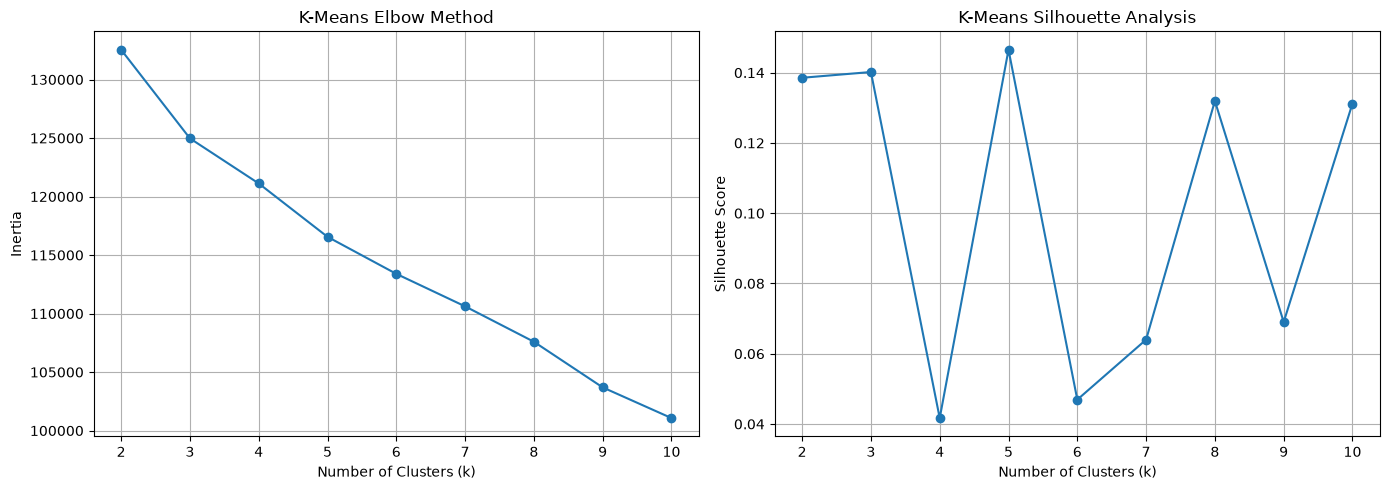

In [19]:
# Step 2: Visualize the results
visualize_kmeans_experiments(experiment_results["results"])

### **``Step 6.3 select optimum number of clusters and and fit model``**

In [22]:
# Step 3: Select k after reviewing the results
selected_k = 3  # Example only; replace with your chosen value.
final_results = fit_kmeans_cluster(X_segmentation_scaled, n_clusters=selected_k,)

### **``Step 6.4 evaluate kMeans cluster model``**

In [23]:
# Step 4: Evaluate the final model
evaluation_results = evaluate_kmeans_cluster(
    X_segmentation_scaled,
    final_results["model"],
    final_results["labels"],
)

display(pd.DataFrame([evaluation_results["metrics"]]))
display(evaluation_results["cluster_sizes"])

,n_clusters,inertia,silhouette_score,davies_bouldin_index
0,3,124971.381691,0.139215,2.036106


,Cluster,Customer_Count,Customer_Percentage
0,0,33,0.624882
1,1,2552,48.324181
2,2,2696,51.050937


### **``Step 6.5 save K-means clustering model``**

**[GO TO INDEX](#INDEX)**

## **``Step 7 GMM clustering experimnets``**

In [16]:
import importlib
import src.segmentation.clustering as clustering
importlib.reload(clustering)
from src.segmentation.clustering import run_gmm_experiments
from src.segmentation.clustering import visualize_gmm_experiments
from src.segmentation.clustering import fit_gmm_cluster
from src.segmentation.clustering import evaluate_gmm_cluster

### **``Step 7.1 GMM clustering experiements``**

In [17]:
# Step 1: Experiment
gmm_experiment = run_gmm_experiments(
    X=X_segmentation_scaled,
    n_components_values=range(2, 11),
    random_state=42,
    n_init=3,
    silhouette_sample_size=2000,
)

gmm_results_df = gmm_experiment["results"]
display(gmm_results_df.round(4))



,n_components,bic,aic,silhouette_score,converged,iterations,smallest_cluster_size
0,2,153069.0705,147358.1148,0.1076,True,12,2162
1,3,66742.0800,58172.3605,0.1025,True,39,742
2,4,-1245.9490,-12674.4322,0.0224,True,26,467
3,5,35206.3580,20919.1109,0.0205,True,26,36
4,6,-8363.5132,-25509.5239,0.0317,True,24,19
5,7,-30541.0206,-50545.7952,0.0156,True,34,14
6,8,-28486.7602,-51350.2986,0.0192,True,29,16
7,9,-35651.8378,-61374.1399,0.0207,True,83,16
8,10,-39597.7141,-68178.7800,-0.0120,True,36,3


### **``Step 7.2 visualise run GMM experiements``**

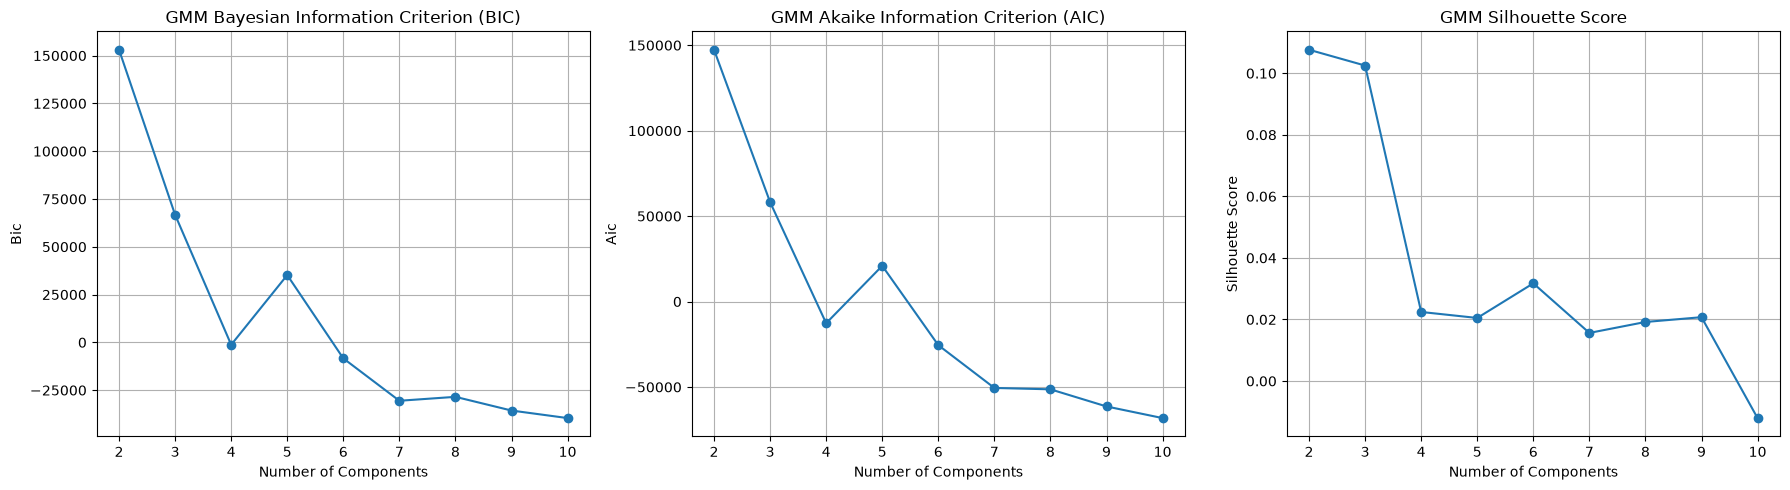

In [18]:
# Step 2: Visualize
visualize_gmm_experiments(gmm_results_df)

### **``Step 7.3 fiting GMM Model``**

In [19]:
# Step 3: Fit the selected model
selected_components = 3  # Choose after reviewing the results

final_gmm_results = fit_gmm_cluster(
    X=X_segmentation_scaled,
    n_components=selected_components,
    random_state=42,
)

final_gmm_model = final_gmm_results["model"]
gmm_labels = final_gmm_results["labels"]

display(final_gmm_results["cluster_sizes"])

,Cluster,Customer_Count,Customer_Percentage
0,0,742,14.050369
1,1,1562,29.577731
2,2,2977,56.371899


### **``Step 7.4 evaluate GMM cluster model``**

In [20]:
# Step 4: Evaluate the final model
gmm_evaluation = evaluate_gmm_cluster(
    X=X_segmentation_scaled,
    model=final_gmm_model,
    labels=gmm_labels,
)

display(pd.DataFrame([gmm_evaluation["metrics"]]))
display(gmm_evaluation["cluster_sizes"])

,n_components,bic,aic,silhouette_score,davies_bouldin_index,converged,iterations
0,3,66742.080007,58172.360546,0.108478,3.340591,True,39


,Cluster,Customer_Count,Customer_Percentage
0,0,742,14.050369
1,1,1562,29.577731
2,2,2977,56.371899


In [21]:
gmm_tied_experiment = run_gmm_experiments(
    X=X_segmentation_scaled,
    n_components_values=range(2, 7),
    covariance_type="tied",
    random_state=42,
    n_init=3,
    silhouette_sample_size=2000,
)

display(gmm_tied_experiment["results"].round(4))

,n_components,bic,aic,silhouette_score,converged,iterations,smallest_cluster_size
0,2,235786.6653,232743.8891,0.1542,True,8,1782
1,3,230193.6179,226960.2575,0.1545,True,7,27
2,4,228131.1907,224707.2460,0.0589,True,6,17
3,5,222587.9460,218973.4171,0.0585,True,7,3
4,6,219175.2522,215370.1390,0.0523,True,15,3


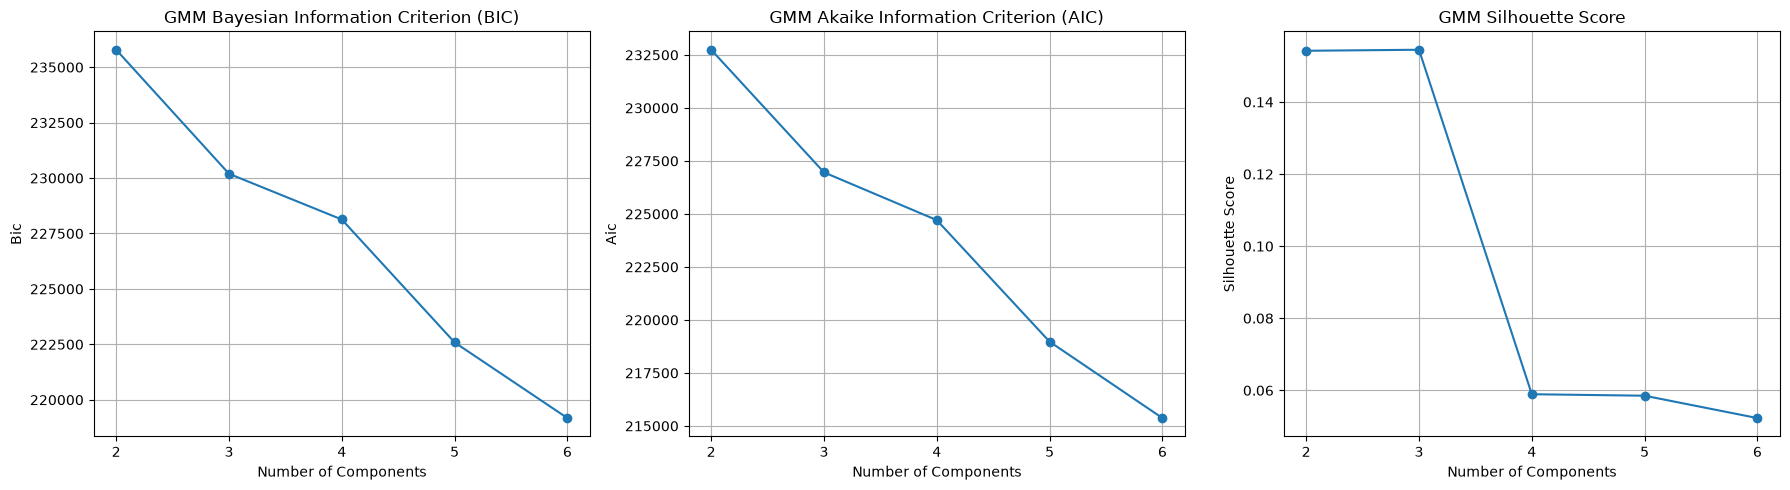

In [22]:
visualize_gmm_experiments(
    gmm_tied_experiment["results"]
)

,n_components,bic,aic,silhouette_score,converged,iterations,smallest_cluster_size
0,2,315863.9633,315121.3419,0.1320,True,16,2393
1,3,259882.2136,258764.9956,0.0803,True,29,908
2,4,171578.7862,170086.9715,0.0396,True,22,518
3,5,166423.3102,164556.8989,0.0082,True,35,360
4,6,128666.6306,126425.6227,-0.0099,True,35,224


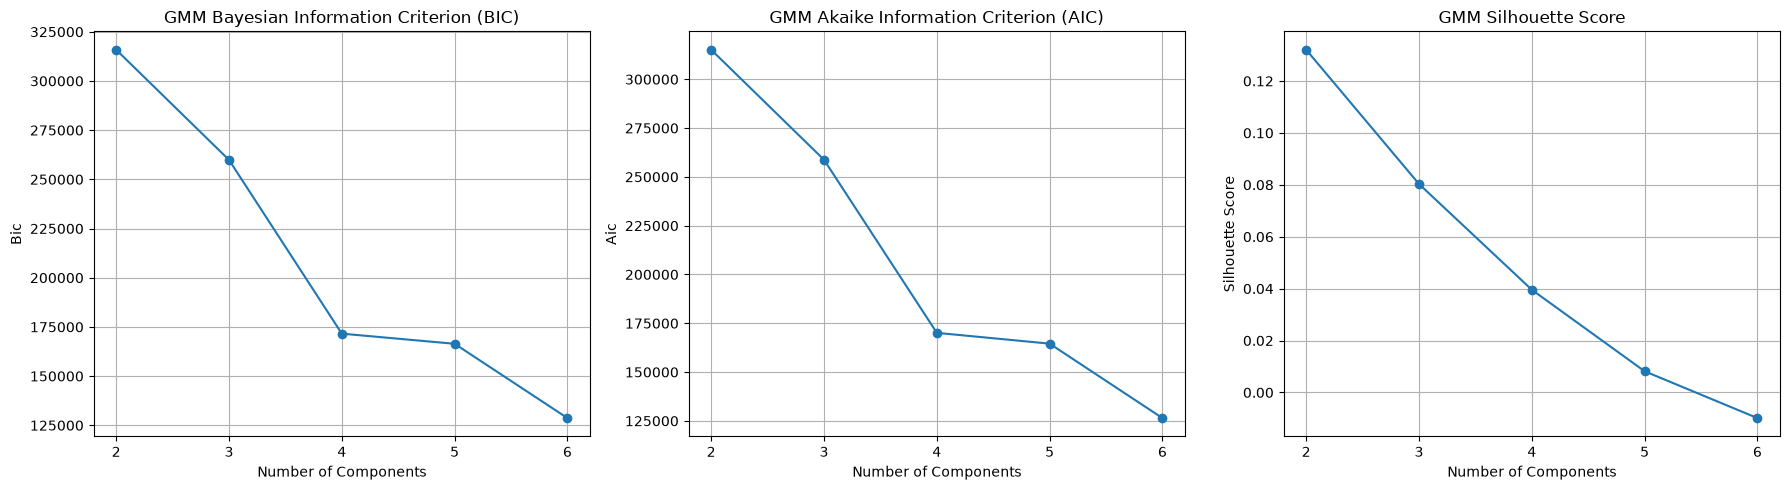

In [23]:
gmm_diag_experiment = run_gmm_experiments(
    X=X_segmentation_scaled,
    n_components_values=range(2, 7),
    covariance_type="diag",
    random_state=42,
    n_init=3,
    silhouette_sample_size=2000,
)

display(gmm_diag_experiment["results"].round(4))

visualize_gmm_experiments(
    gmm_diag_experiment["results"]
)

In [24]:
selected_components = 2

final_gmm_results = fit_gmm_cluster(
    X=X_segmentation_scaled,
    n_components=selected_components,
    covariance_type="tied",
    random_state=42,
)

final_gmm_model = final_gmm_results["model"]
gmm_labels = final_gmm_results["labels"]

display(final_gmm_results["cluster_sizes"])

,Cluster,Customer_Count,Customer_Percentage
0,0,1782,33.743609
1,1,3499,66.256391


In [25]:
gmm_evaluation = evaluate_gmm_cluster(
    X=X_segmentation_scaled,
    model=final_gmm_model,
    labels=gmm_labels,
)

display(pd.DataFrame([gmm_evaluation["metrics"]]))

,n_components,bic,aic,silhouette_score,davies_bouldin_index,converged,iterations
0,2,235786.665253,232743.889094,0.158108,2.663444,True,8


## **``Step 7.5 Save GMM Clustering model artifacts:``**

In [26]:
from src.models.model_persistance import save_model_artifact

gmm_model_name = "gmm_customer_segmentation"

gmm_preprocessing = {
    "scaler": segmentation_scaler,
    "feature_names": list(X_segmentation.columns),
}

gmm_artifact_paths = save_model_artifact(
    model=final_gmm_model,
    model_name=gmm_model_name,
    model_type="clustering",
    config=config,
    preprocessing=gmm_preprocessing,
    metadata={
        "algorithm": "GaussianMixture",
        "n_components": 2,
        "covariance_type": "tied",
        "random_state": 42,
        "feature_names": list(X_segmentation.columns),
    },
)

print("GMM artifacts saved:")
for artifact_name, artifact_path in gmm_artifact_paths.items():
    print(f"{artifact_name}: {artifact_path}")


GMM artifacts saved:
model_path: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\models\clustering\gmm_customer_segmentation\gmm_customer_segmentation_artifact.joblib
preprocessing_path: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\models\clustering\gmm_customer_segmentation\gmm_customer_segmentation_preprocessing.joblib
metadata_path: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\models\clustering\gmm_customer_segmentation\gmm_customer_segmentation_metadata.joblib


**[GO TO INDEX](#INDEX)**

## **``Step 8 DBSCAN clustering experimnets``**

In [37]:
import importlib
import src.segmentation.clustering as clustering
importlib.reload(clustering)
from src.segmentation.clustering import run_dbscan_experiments
from src.segmentation.clustering import visualize_dbscan_experiments
from src.segmentation.clustering import fit_dbscan_cluster
from src.segmentation.clustering import evaluate_dbscan_cluster


### **``Step 8.1 DBSCAN clustering experiements``**

In [38]:
# Step 1: Experiment
dbscan_experiment = run_dbscan_experiments(
    X=X_segmentation_scaled,
    eps_values=(2.0, 3.0, 4.0, 5.0, 6.0),
    min_samples_values=(5, 10, 20),
)

dbscan_results_df = dbscan_experiment["results"]
display(dbscan_results_df.round(4))


,eps,min_samples,n_clusters,noise_count,noise_percentage,assigned_count,silhouette_score,davies_bouldin_index
0,2.0,5,15,2918,55.2547,2363,-0.0482,0.7490
1,2.0,10,4,3333,63.1130,1948,0.0321,1.1345
2,2.0,20,4,3746,70.9335,1535,0.2252,1.2024
3,3.0,5,3,586,11.0964,4695,0.5242,0.5056
4,3.0,10,2,707,13.3876,4574,0.4562,0.6427
5,3.0,20,1,929,17.5914,4352,NaN,NaN
6,4.0,5,3,193,3.6546,5088,0.3088,1.1565
7,4.0,10,1,238,4.5067,5043,NaN,NaN
8,4.0,20,1,282,5.3399,4999,NaN,NaN
9,5.0,5,2,79,1.4959,5202,0.7170,0.3464


### **``Step 8.2 visualise run DBSCAN  experiements``**

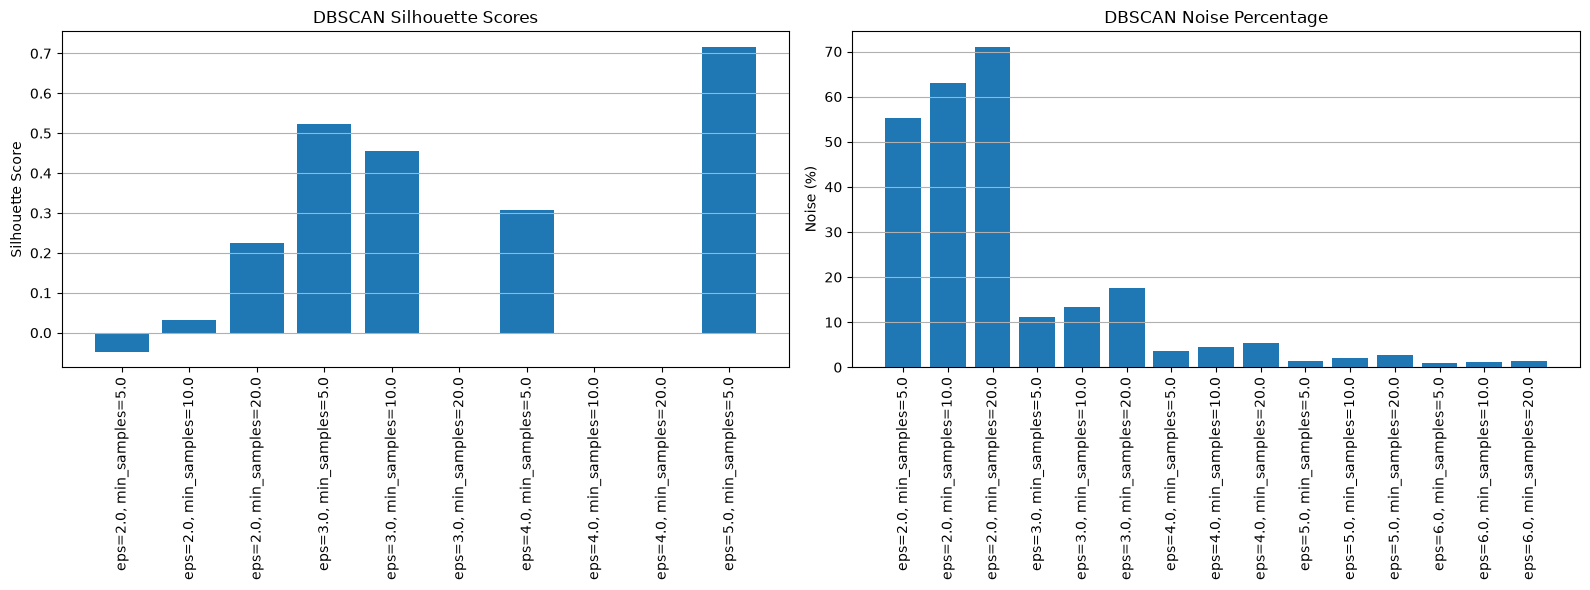

In [39]:
# Step 2: Visualize
visualize_dbscan_experiments(dbscan_results_df)

### **``Step 8.3 fiting DBSCAN  Model``**

In [40]:
# Step 3: Fit selected DBSCAN configuration.
# Example values only; choose after reviewing the experiment table.

selected_eps = 3.0
selected_min_samples = 10

final_dbscan_results = fit_dbscan_cluster(
    X=X_segmentation_scaled,
    eps=selected_eps,
    min_samples=selected_min_samples,
)

final_dbscan_model = final_dbscan_results["model"]
dbscan_labels = final_dbscan_results["labels"]

display(final_dbscan_results["cluster_sizes"])


,Cluster,Customer_Count,Customer_Percentage
0,-1,707,13.387616
1,0,4559,86.328347
2,1,15,0.284037


### **``Step 8.4 evaluate DBSCAN  cluster model``**

In [41]:
# Step 4: Evaluate
dbscan_evaluation = evaluate_dbscan_cluster(X=X_segmentation_scaled, labels=dbscan_labels,)
display(pd.DataFrame([dbscan_evaluation["metrics"]]))
display(dbscan_evaluation["cluster_sizes"])

,n_clusters_excluding_noise,noise_count,noise_percentage,assigned_count,silhouette_score_excluding_noise,davies_bouldin_index_excluding_noise
0,2,707,13.387616,4574,0.456176,0.642666


,Cluster,Customer_Count,Customer_Percentage
0,-1,707,13.387616
1,0,4559,86.328347
2,1,15,0.284037


In [46]:

dbscan_candidate_results = {}

for params in dbscan_candidates:
    result = fit_dbscan_cluster(
        X=X_segmentation_scaled,
        eps=params["eps"],
        min_samples=params["min_samples"],
    )

    model = result["model"]
    labels = result["labels"]
    cluster_sizes = result["cluster_sizes"]

    print(f"\nParameters: {params}")
    print("Input rows:", len(X_segmentation_scaled))
    print("Label count:", len(labels))
    print("Cluster sizes:")
    display(cluster_sizes)

    evaluation = evaluate_dbscan_cluster(
        X=X_segmentation_scaled,
        labels=labels,
    )

    key = (params["eps"], params["min_samples"])

    dbscan_candidate_results[key] = {
        "model": model,
        "labels": labels,
        "cluster_sizes": cluster_sizes,
        "evaluation": evaluation,
    }

    print("Evaluation:")
    display(evaluation)



Parameters: {'eps': 3.0, 'min_samples': 5}
Input rows: 5281
Label count: 5281
Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,-1,586,11.096383
1,0,4679,88.600644
2,1,11,0.208294
3,2,5,0.094679


Evaluation:


{'metrics': {'n_clusters_excluding_noise': 3,
  'noise_count': 586,
  'noise_percentage': 11.096383260746071,
  'assigned_count': 4695,
  'silhouette_score_excluding_noise': 0.5242009979602743,
  'davies_bouldin_index_excluding_noise': 0.5056203116653221},
 'cluster_sizes':    Cluster  Customer_Count  Customer_Percentage
 0       -1             586            11.096383
 1        0            4679            88.600644
 2        1              11             0.208294
 3        2               5             0.094679}


Parameters: {'eps': 5.0, 'min_samples': 5}
Input rows: 5281
Label count: 5281
Cluster sizes:


,Cluster,Customer_Count,Customer_Percentage
0,-1,79,1.495929
1,0,5197,98.409392
2,1,5,0.094679


Evaluation:


{'metrics': {'n_clusters_excluding_noise': 2,
  'noise_count': 79,
  'noise_percentage': 1.495928801363378,
  'assigned_count': 5202,
  'silhouette_score_excluding_noise': 0.7169888475737849,
  'davies_bouldin_index_excluding_noise': 0.3463687278579432},
 'cluster_sizes':    Cluster  Customer_Count  Customer_Percentage
 0       -1              79             1.495929
 1        0            5197            98.409392
 2        1               5             0.094679}

In [47]:

# Verify row alignment before profiling
assert len(customer_features) == len(X_segmentation_scaled)

profile_columns = [
    "Recency",
    "Frequency",
    "Total_Monetary_Value",
    "Average_Order_Spend",
    "Average_Basket_Size",
    "Return_Rate",
    "Discount_Markdown_Sensitivity",
    "Engagement_Score",
]

for key, result in dbscan_candidate_results.items():
    labels = result["labels"]

    profile_df = customer_features[profile_columns].copy()
    profile_df["Cluster"] = np.asarray(labels)

    print(f"\nDBSCAN parameters: eps={key[0]}, min_samples={key[1]}")
    print("\nCluster counts:")
    display(
        profile_df["Cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .to_frame("Customer_Count")
    )

    print("\nMedian customer profile:")
    display(
        profile_df.groupby("Cluster")[profile_columns]
        .median()
        .round(2)
    )



DBSCAN parameters: eps=3.0, min_samples=5

Cluster counts:


,Customer_Count
Cluster,
-1,586
0,4679
1,11
2,5



Median customer profile:


,Recency,Frequency,Total_Monetary_Value,Average_Order_Spend,Average_Basket_Size,Return_Rate,Discount_Markdown_Sensitivity,Engagement_Score
Cluster,,,,,,,,
-1,171.98,2.0,661.90,285.16,171.17,0.0,0.03,46.49
0,163.86,3.0,799.13,276.68,147.00,0.0,0.00,49.47
1,436.98,1.0,85.00,85.00,31.00,0.0,0.00,13.50
2,113.08,1.0,358.56,358.56,201.00,0.0,0.14,38.75



DBSCAN parameters: eps=5.0, min_samples=5

Cluster counts:


,Customer_Count
Cluster,
-1,79
0,5197
1,5



Median customer profile:


,Recency,Frequency,Total_Monetary_Value,Average_Order_Spend,Average_Basket_Size,Return_Rate,Discount_Markdown_Sensitivity,Engagement_Score
Cluster,,,,,,,,
-1,117.97,4.0,6414.32,553.20,460.0,0.14,0.11,63.79
0,164.10,3.0,777.34,275.49,146.7,0.00,0.00,48.76
1,319.12,1.0,152.35,93.35,43.0,0.00,0.00,24.82


**[GO TO INDEX](#INDEX)**

### **``============================= END OF SEGMENTATION ===================================``**